# Plot saved experiments

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from config import make_config, describe
import utils as U

OVERRIDES = {}
cfg = make_config(**OVERRIDES)
describe(cfg)

# Save generated plots in a figures/ directory at the repository root
# (run this notebook with the repository root as the working directory).
FIGURES_DIR = Path.cwd() / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(filename):
    plt.gcf().savefig(FIGURES_DIR / filename, dpi=300, bbox_inches="tight")

U.apply_style()
print("OT backend:", U.ot_backend())

Using config.py defaults.
OT backend: POT available; SciPy assignment used for equal-weight square problems


In [12]:
conv_path = U.convergence_path(cfg)
conv = pd.read_csv(conv_path) if conv_path.exists() else None
found = set(conv["experiment"].unique()) if conv is not None else set()
print("convergence experiments found:", sorted(found) or "none")

MNIST_VARIANT = cfg.mnist_variant
mnist_files = sorted((cfg.results_dir / "mnist").glob("*.csv"))
print("mnist files found:", [p.name for p in mnist_files] or "none")

bayes_ready = (U.bayes_dir(cfg) / "raw_results.npz").exists()
print("bayes results found:", bayes_ready)

convergence experiments found: ['centre_only', 'fixed_c', 'fixed_n_control', 'joint_growth']
mnist files found: ['mnist.csv']
bayes results found: True


---
## Ring distribution plot

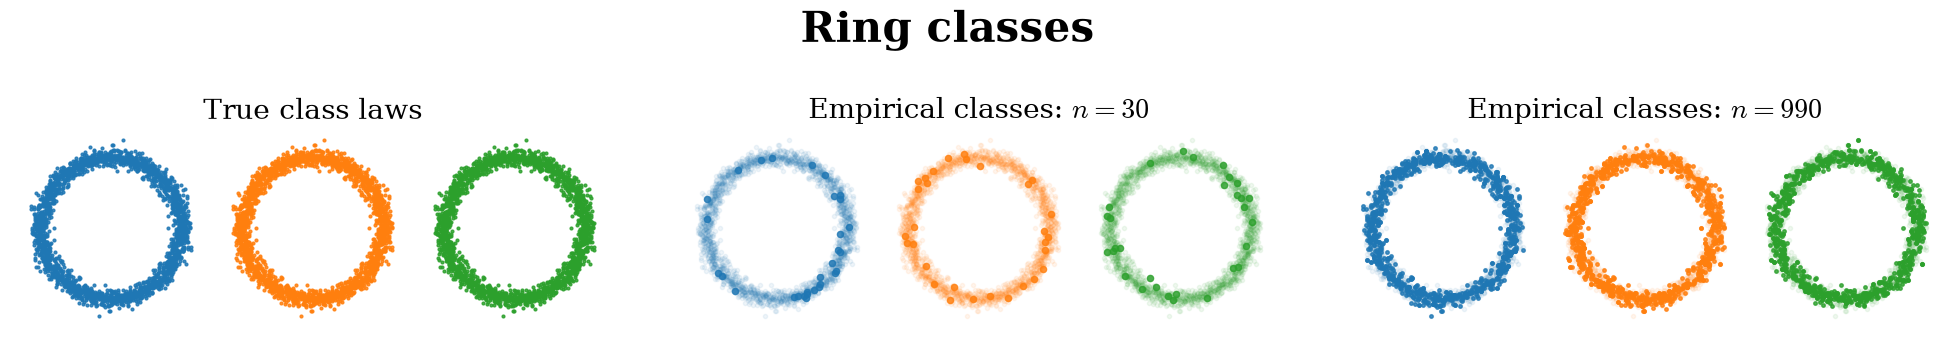

In [13]:
U.plot_ring_schematic(cfg)
save_figure("ring_schematic.png")
plt.show()

## Experiment 1 — fixed class count

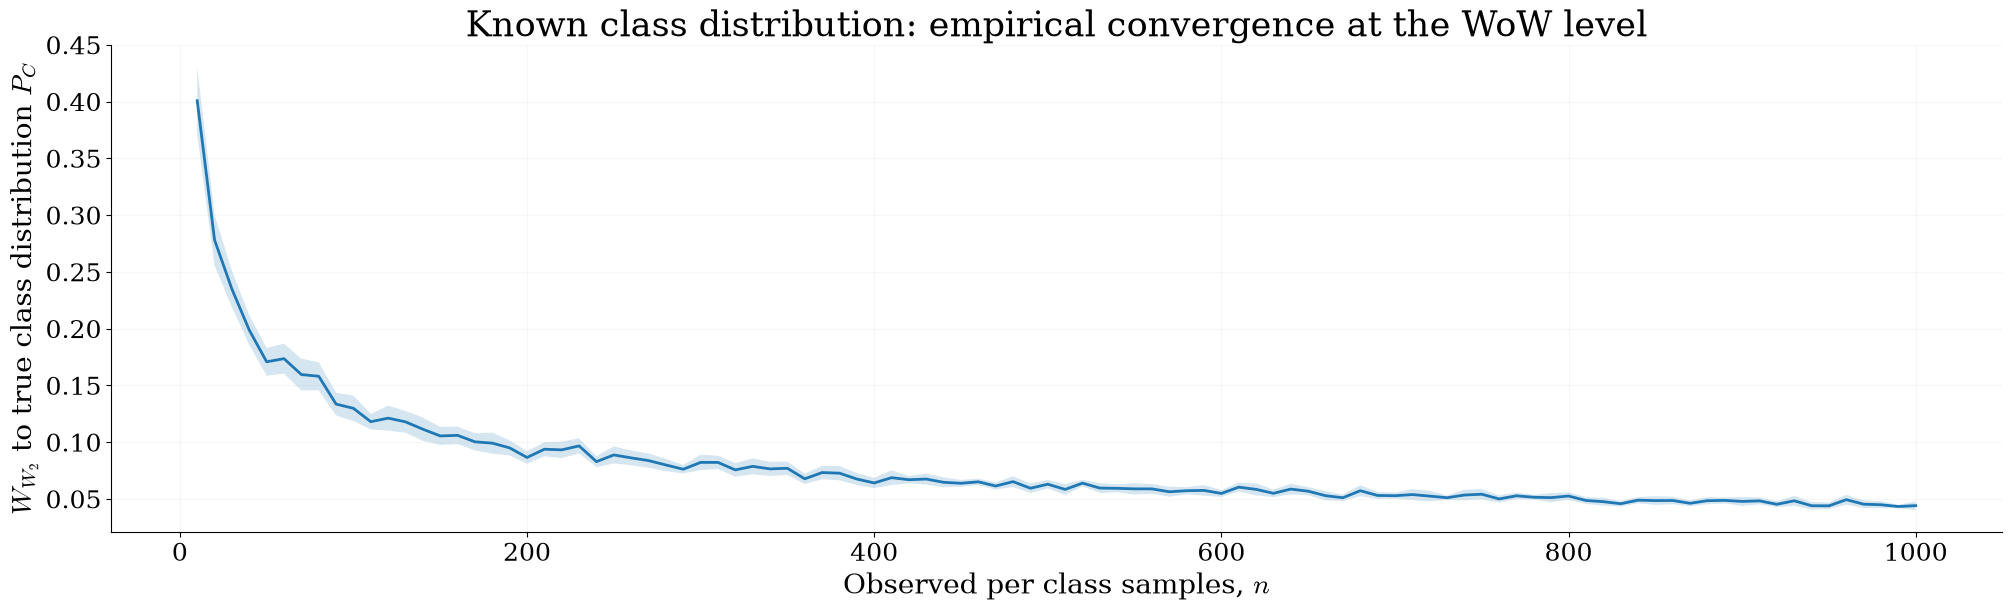

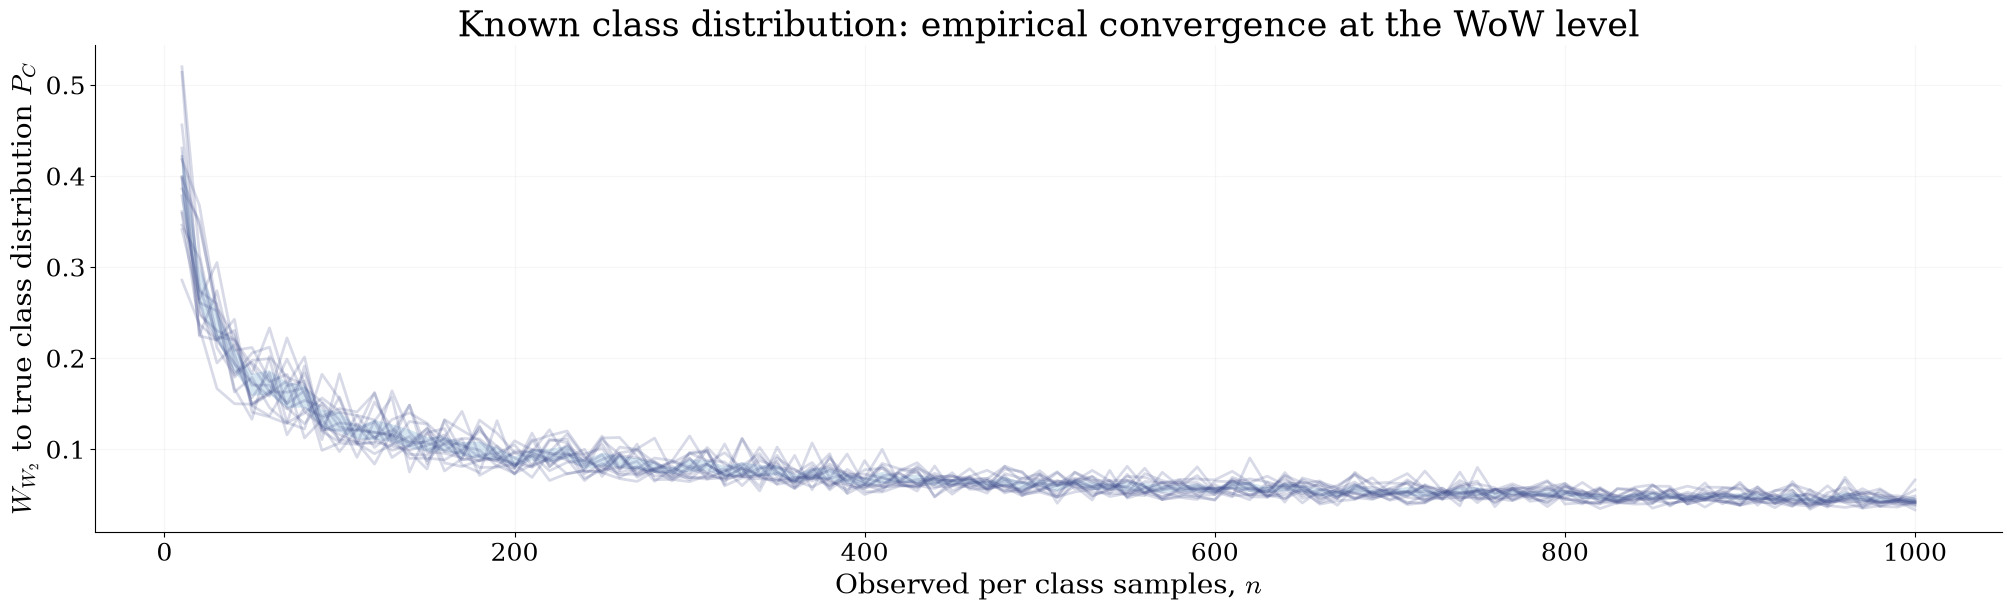

In [14]:
if "fixed_c" in found:
    U.plot_fixed_c(conv); save_figure("fixed_c.png"); plt.show()
    U.plot_fixed_c(conv, individual=True); save_figure("fixed_c_individual.png"); plt.show()
else:
    print("No fixed-C results saved")

## Experiment 2 — growing class count

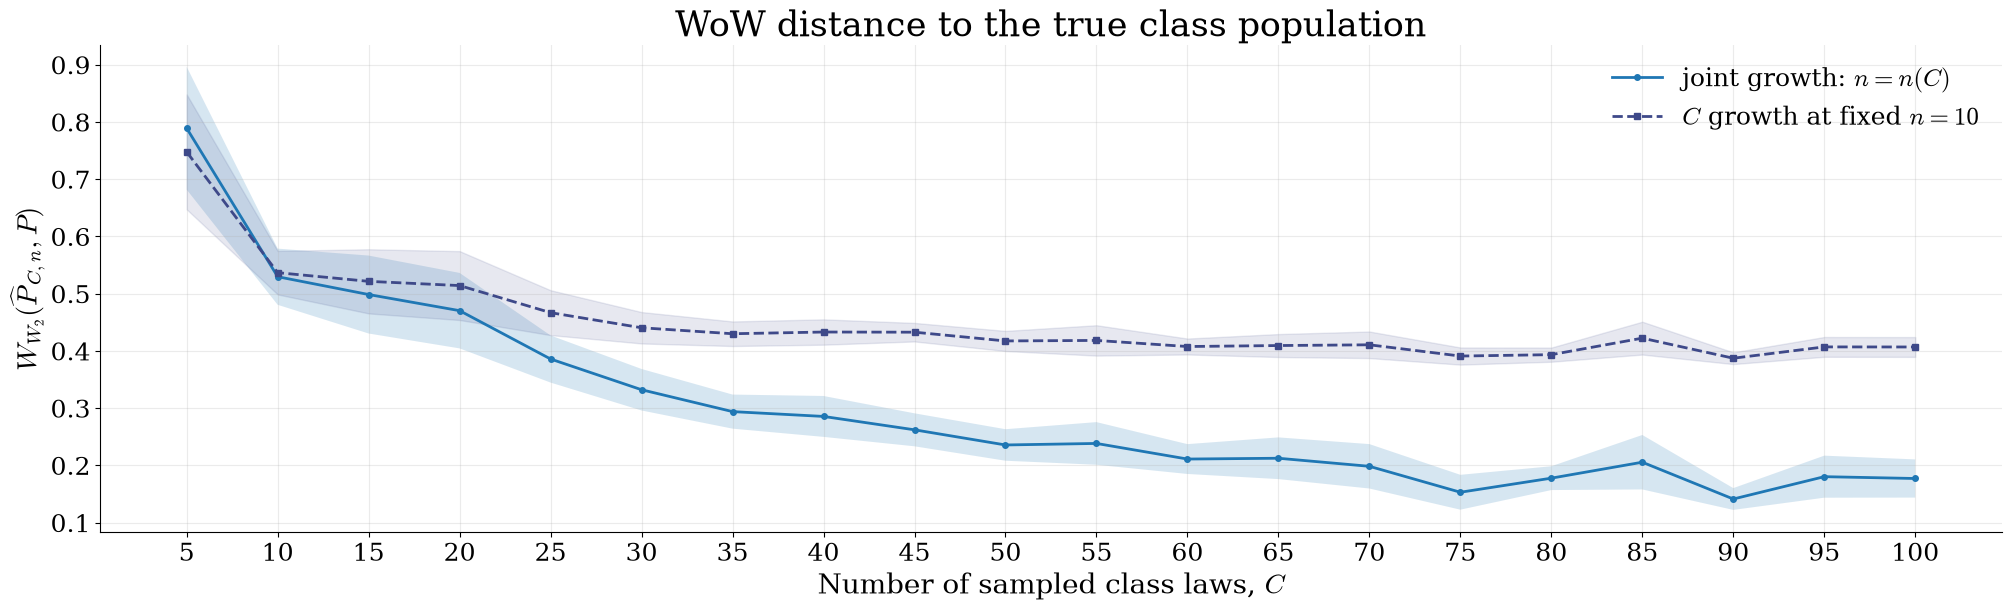

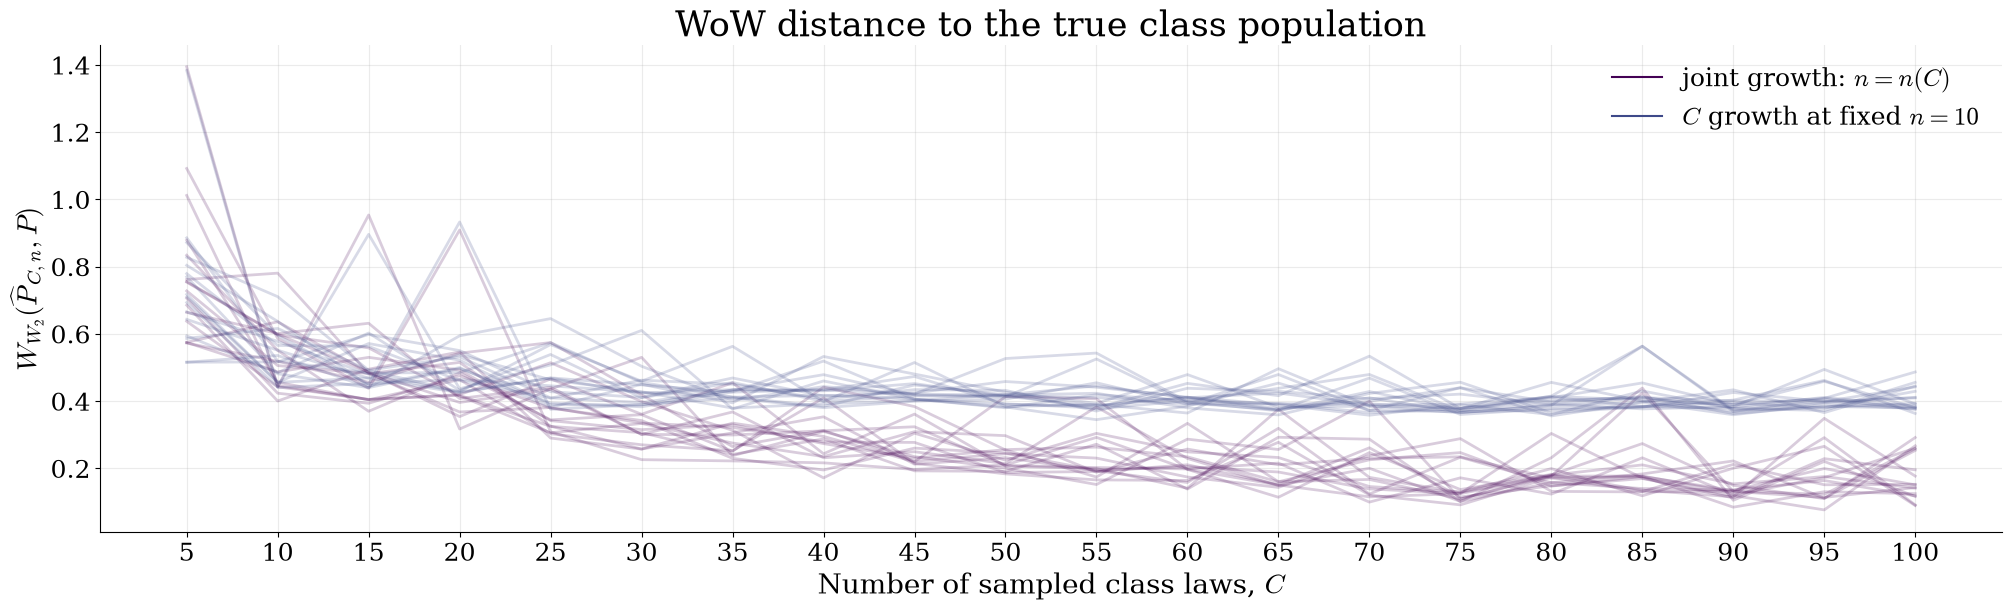

In [15]:
if {"joint_growth", "fixed_n_control", "centre_only"} <= found:
    U.plot_growing_c(conv); save_figure("growing_c.png"); plt.show()
    U.plot_growing_c(conv, individual=True); save_figure("growing_c_individual.png"); plt.show()
else:
    print("No (complete) growing-C results saved")

## Experiment 3 — MNIST-family empirical diagnostic

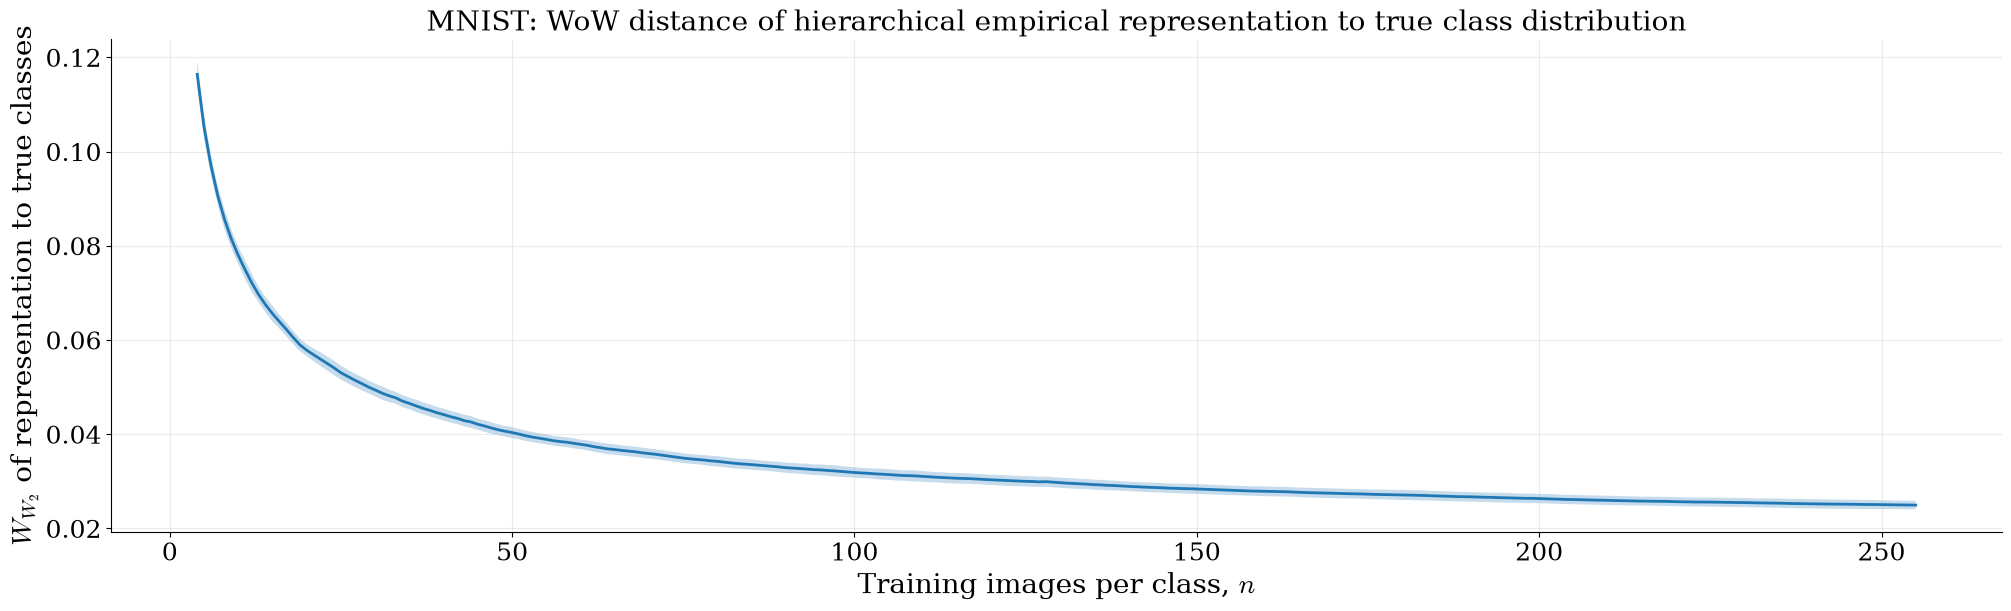

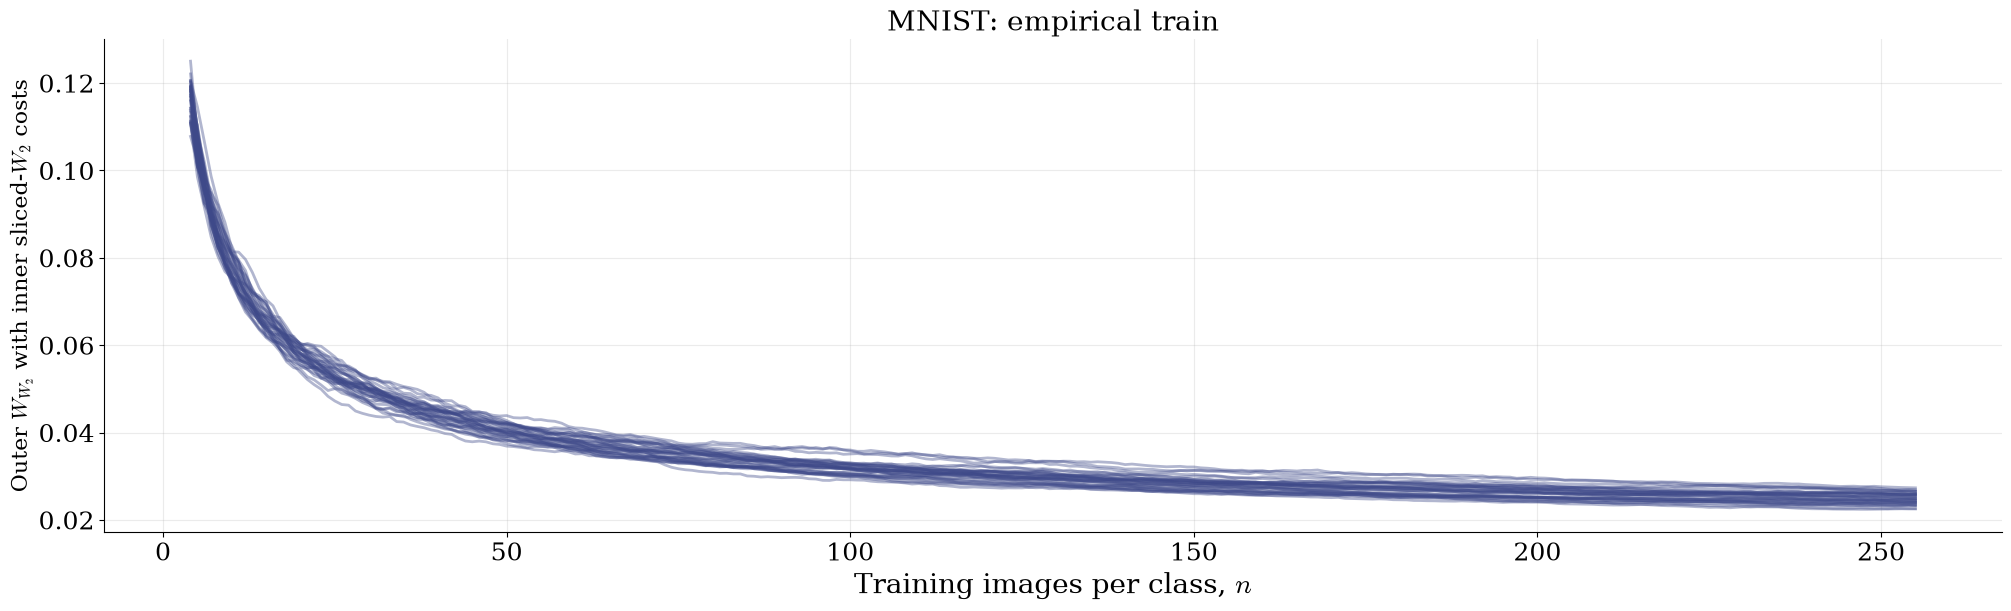

In [16]:
mnist_path = U.mnist_path(cfg, MNIST_VARIANT)
if mnist_path.exists():
    mnist = pd.read_csv(mnist_path)
    U.plot_mnist(mnist); save_figure("mnist.png"); plt.show()
    U.plot_mnist(mnist, individual=True); save_figure("mnist_individual.png"); plt.show()
else:
    print(f"No saved results at {mnist_path}")

## Experiment 4 — Bayesian hyperpriors

In [17]:
res = U.load_bayes_results(U.bayes_dir(cfg))

print("Available epsilons:", res["epsilons"])

summ = U.bayes_summaries(res)

Available epsilons: [0.05 0.1  0.15 0.2  0.25]


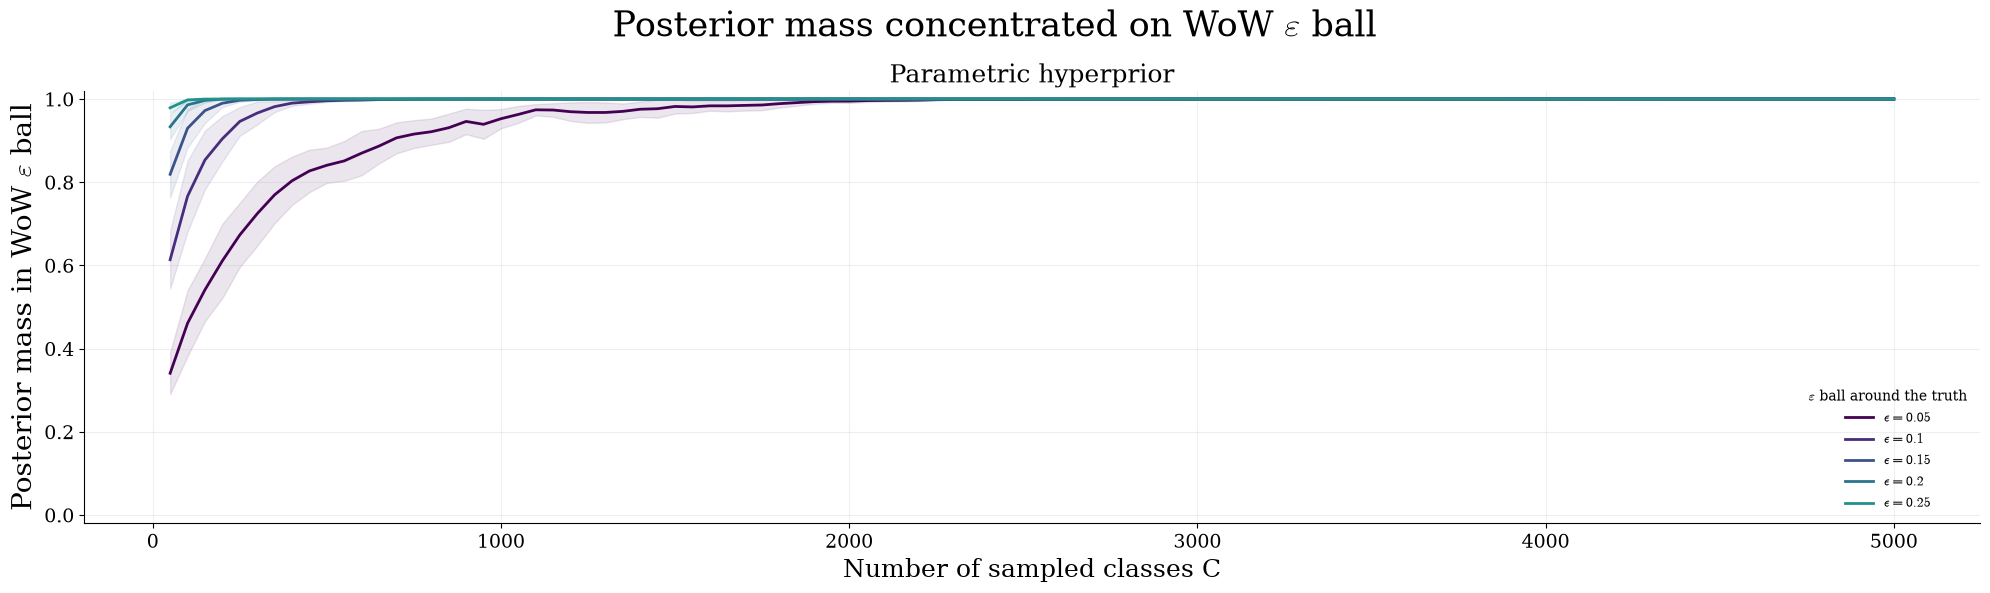

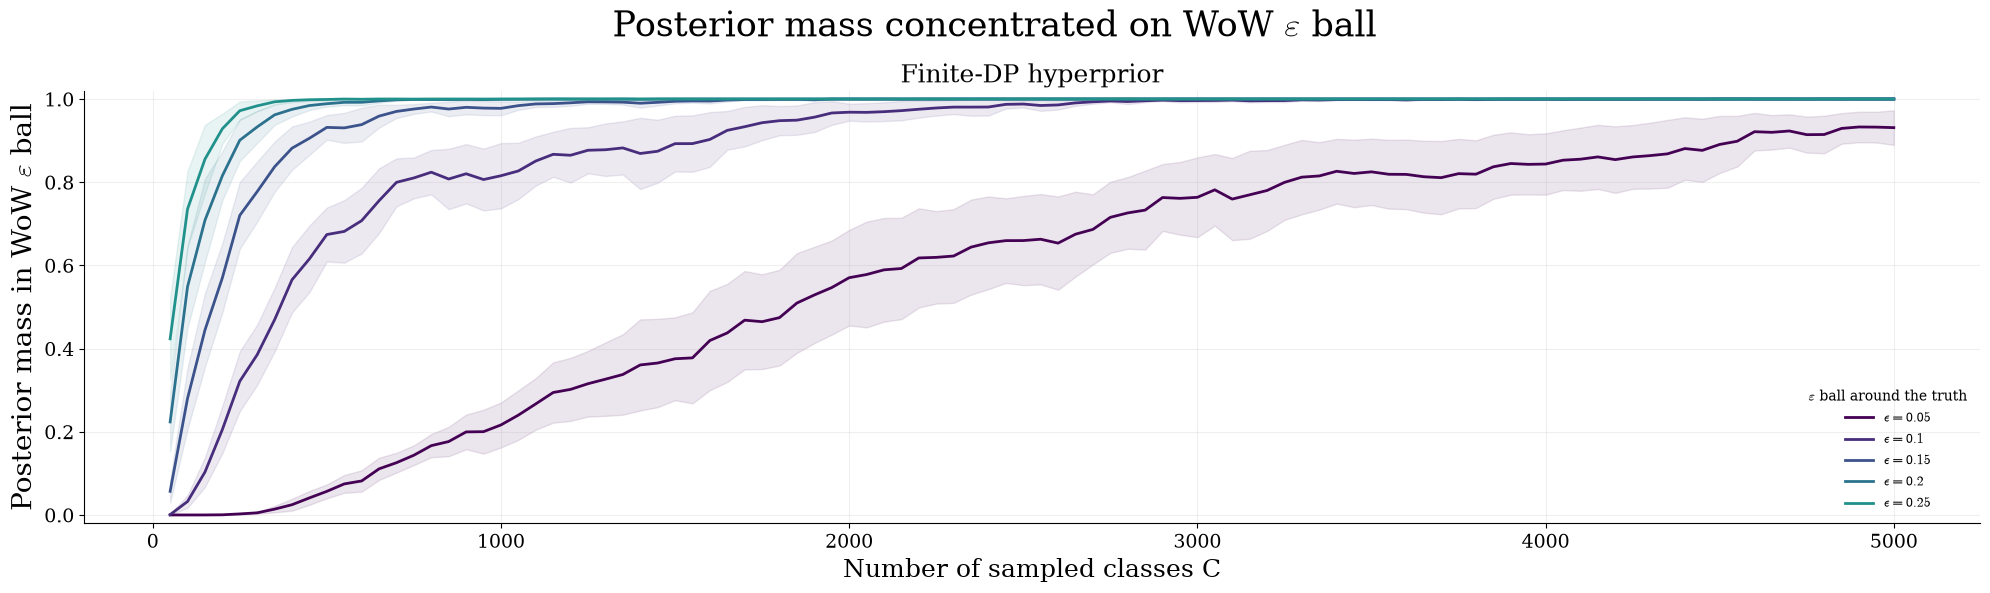

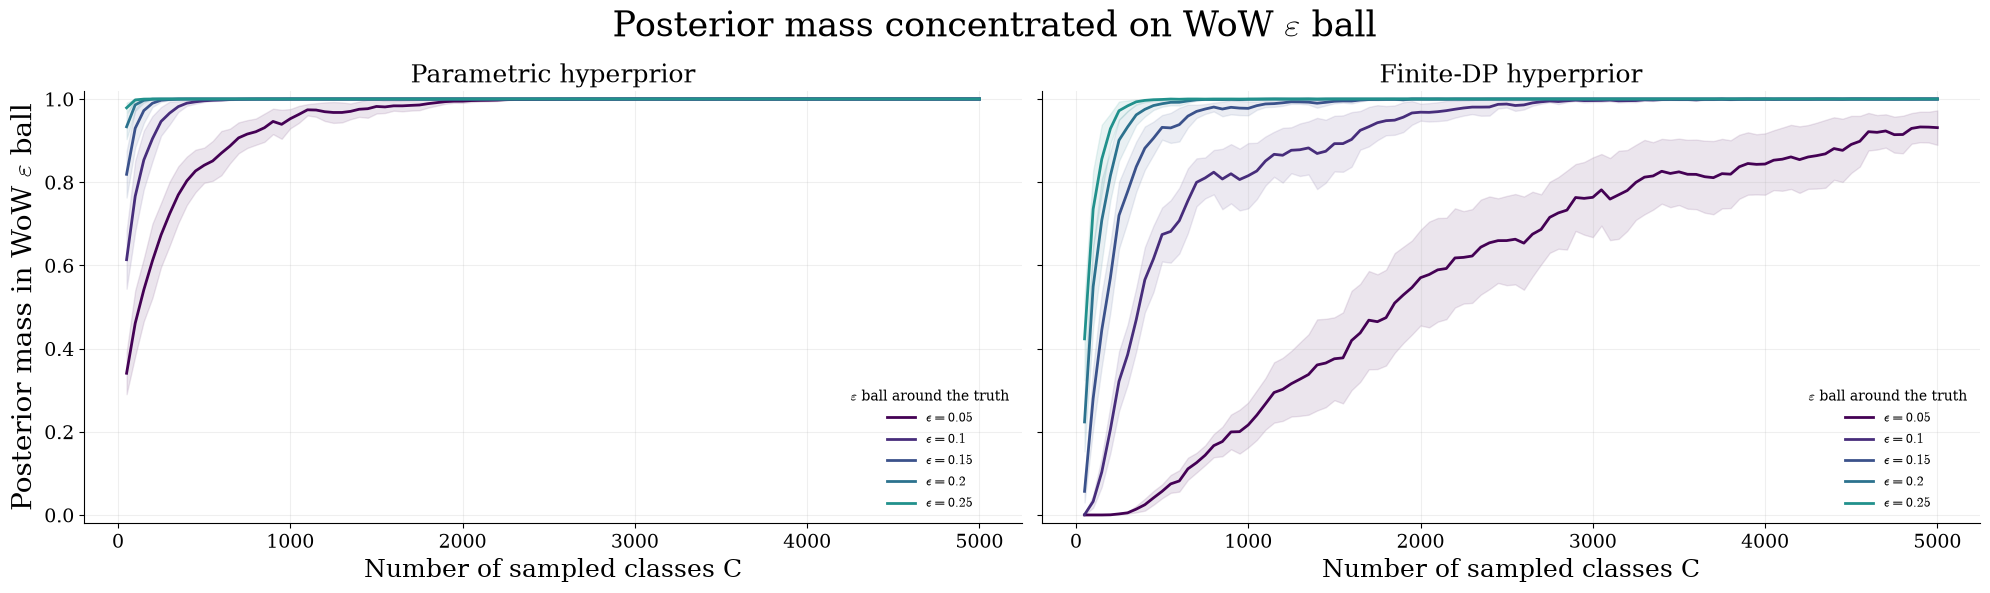

In [18]:
# Lines with 95% CI
U.plot_bayes_mass_all_epsilons(res, summ, "param", show_ci=True)
save_figure("bayes_mass_all_epsilons_param_ci.png")
plt.show()

# Repeat for the finite-DP model
U.plot_bayes_mass_all_epsilons(res, summ, "dp", show_ci=True)
save_figure("bayes_mass_all_epsilons_dp_ci.png")
plt.show()

U.plot_bayes_mass_all_epsilons(
    res, summ, model="both", show_ci=True
)
save_figure("bayes_mass_all_epsilons_both_ci.png")
plt.show()